<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 1 · Sesión 3: Organización, segmentación, indicadores y gobierno del riesgo minorista</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: matriz de segmentación, FPD/30@3, cura y roll rates, facultades, champion–challenger y tablero ejecutivo</div>
</div>

## Objetivos de la sesión (2 horas)

1. Segmentar la cartera por **producto, cliente y portafolio**, y leer riesgo y rentabilidad en una misma matriz.
2. Construir los **indicadores del ciclo de crédito** que usa cada área: originación, seguimiento, cobranza y recuperación.
3. Diseñar una **matriz de facultades (autonomías)** y medir su efecto.
4. Simular el **gobierno de un cambio de política** con un esquema *champion–challenger*.
5. Armar un **tablero ejecutivo** de riesgo, crecimiento y rentabilidad.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 25 min | Segmentación de cartera |
| 2 | 30 min | Indicadores por etapa del ciclo |
| 3 | 20 min | Facultades y excepciones |
| 4 | 20 min | Champion–challenger y gobierno de cambios |
| 5 | 15 min | Tablero ejecutivo |
| 6 | 10 min | Caso de discusión |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

In [2]:
p = pd.read_csv(DATA / "cartera_panel_mensual.csv.gz")
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
vig = p[p.estado == "Vigente"]
CORTE = "2026-06"
print(p.shape, app.shape)

(286560, 17) (60060, 26)


## 1. Segmentación de cartera
Una buena segmentación cumple tres condiciones: **homogeneidad interna** (riesgo parecido dentro del segmento), **heterogeneidad entre segmentos** y **accionabilidad** (cada segmento tiene una estrategia distinta).

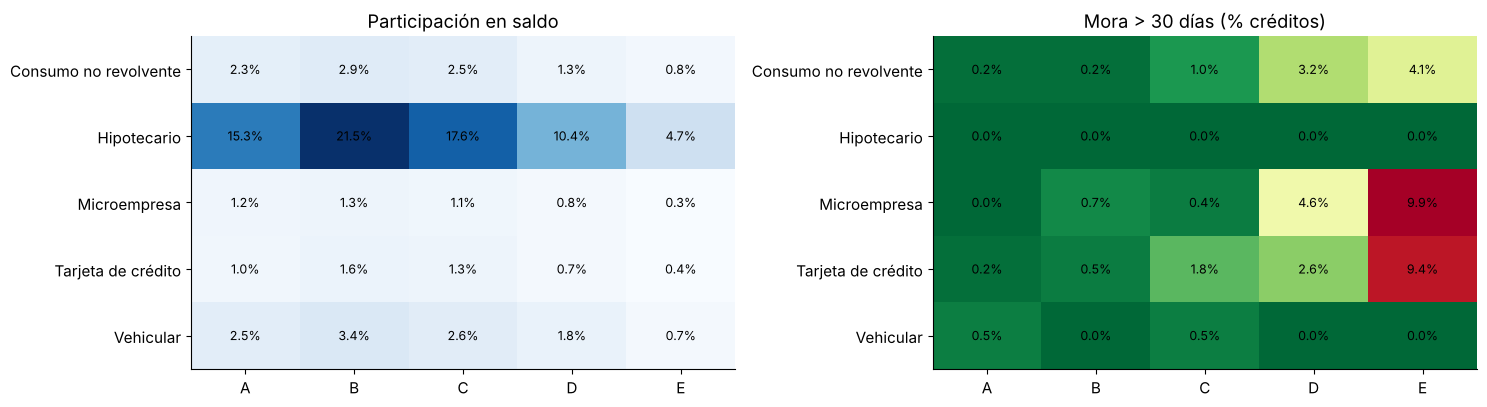

In [3]:
foto = vig[vig.periodo == CORTE]
seg = foto.groupby(["producto", "segmento_riesgo"]).agg(saldo=("saldo", "sum"), n=("saldo", "size"),
        mora=("dias_atraso", lambda s: (s > 30).mean()))
seg["part_saldo"] = seg.saldo / seg.saldo.sum()
mat_mora = seg.mora.unstack()
mat_part = seg.part_saldo.unstack()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
import matplotlib.colors as mcolors
for a, m, t, fmt, cmap in [(ax[0], mat_part, "Participación en saldo", "{:.1%}", "Blues"), (ax[1], mat_mora, "Mora > 30 días (% créditos)", "{:.1%}", "RdYlGn_r")]:
    im = a.imshow(m.values, cmap=cmap, aspect="auto")
    a.set_xticks(range(m.shape[1])); a.set_xticklabels(m.columns); a.set_yticks(range(m.shape[0])); a.set_yticklabels(m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            a.text(j, i, fmt.format(m.values[i, j]), ha="center", va="center", fontsize=9)
    a.set_title(t); a.grid(False)
plt.tight_layout(); plt.show()

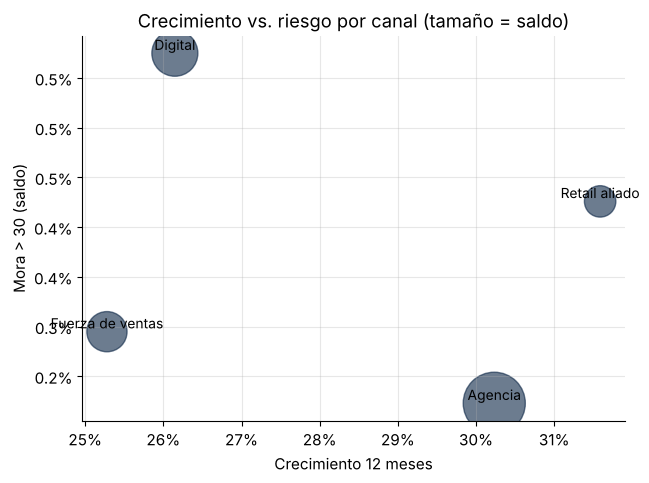

In [4]:
# Segmentación por canal y región: ¿dónde crecer?
crec = vig[vig.periodo.isin(["2025-06", CORTE])].groupby(["canal", "periodo"]).saldo.sum().unstack()
crec["crec_12m"] = crec[CORTE] / crec["2025-06"] - 1
crec["mora_actual"] = foto.groupby("canal").apply(lambda d: d.loc[d.dias_atraso > 30, "saldo"].sum() / d.saldo.sum())
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(crec.crec_12m, crec.mora_actual, s=crec[CORTE] / crec[CORTE].max() * 2000, color=AZUL, alpha=.6)
for k, r in crec.iterrows(): ax.annotate(k, (r.crec_12m, r.mora_actual), ha="center", va="bottom", fontsize=10)
ax.set_xlabel("Crecimiento 12 meses"); ax.set_ylabel("Mora > 30 (saldo)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.set_title("Crecimiento vs. riesgo por canal (tamaño = saldo)"); plt.show()

> **Pregunta:** el canal que más crece ¿es el más riesgoso? Si crecer en *Retail aliado* duplica la mora, ¿qué exigirías: precio, límite o score diferenciado?

## 2. Indicadores por etapa del ciclo de crédito

| Etapa | Indicador | Pregunta que responde |
|---|---|---|
| Originación | Tasa de aprobación, ticket promedio, **FPD** (*first payment default*), **30@3** / **60@6** | ¿Estamos aprobando bien? |
| Seguimiento | % cartera al día, entradas a mora 1-30, migración de categorías | ¿Se está deteriorando la cartera viva? |
| Cobranza | **Roll rate** 1-30 → 31-60, **tasa de cura**, saldo en tramos tardíos | ¿La cobranza contiene la mora? |
| Recuperación | Castigos, **tasa de recupero** post-castigo, LGD observada | ¿Cuánto recuperamos de lo perdido? |

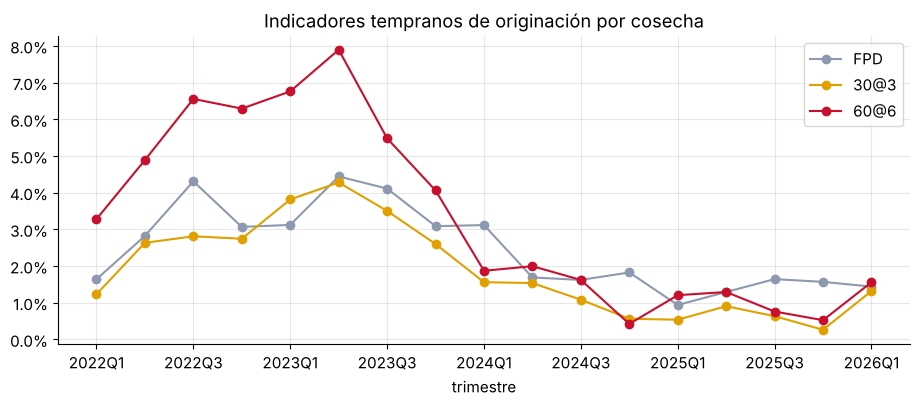

In [5]:
# --- Originación: FPD y 30@3 por cosecha (indicadores tempranos de calidad de admisión)
pc = p[p.producto.isin(["Tarjeta de crédito", "Consumo no revolvente", "Microempresa"])]
mob = pc.pivot_table(index="id_credito", columns="mob", values="dias_atraso", aggfunc="max")
info = pc.drop_duplicates("id_credito").set_index("id_credito")[["cosecha", "producto"]]
info["FPD"] = (mob[1] > 0) if 1 in mob else np.nan            # atraso en la primera cuota
info["30@3"] = (mob.loc[:, 1:3].max(axis=1) > 30)
info["60@6"] = (mob.loc[:, 1:6].max(axis=1) > 60)
info["maduro6"] = mob.loc[:, 1:6].notna().sum(axis=1) == 6
temp = info[info.maduro6].assign(trimestre=lambda d: pd.PeriodIndex(d.cosecha, freq="M").asfreq("Q").astype(str))
ti = temp.groupby("trimestre")[["FPD", "30@3", "60@6"]].mean()
ax = ti.plot(marker="o", figsize=(11, 4), color=[GRIS, ORO, ROJO]); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.set_title("Indicadores tempranos de originación por cosecha"); plt.show()

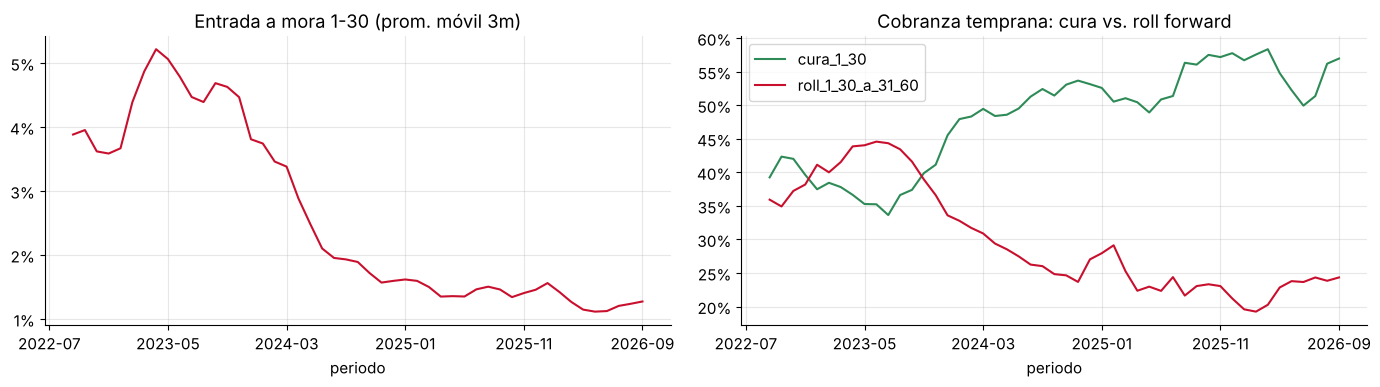

In [6]:
# --- Seguimiento y cobranza: entradas a mora y tasa de cura mensual
pr = p[(p.estado == "Vigente")].sort_values(["id_credito", "mob"]).copy()
pr["b_prev"] = pr.groupby("id_credito").bucket_atraso.shift(1)
t = pr.dropna(subset=["b_prev"]).groupby("periodo").apply(lambda d: pd.Series({
    "entrada_mora": ((d.b_prev == "0") & (d.bucket_atraso == "1-30")).sum() / (d.b_prev == "0").sum(),
    "cura_1_30": ((d.b_prev == "1-30") & (d.bucket_atraso == "0")).sum() / max((d.b_prev == "1-30").sum(), 1),
    "roll_1_30_a_31_60": ((d.b_prev == "1-30") & (d.bucket_atraso == "31-60")).sum() / max((d.b_prev == "1-30").sum(), 1),
})).loc["2022-07":]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
t.entrada_mora.rolling(3).mean().plot(ax=ax[0], color=ROJO); ax[0].set_title("Entrada a mora 1-30 (prom. móvil 3m)")
t[["cura_1_30", "roll_1_30_a_31_60"]].rolling(3).mean().plot(ax=ax[1], color=[VERDE, ROJO]); ax[1].set_title("Cobranza temprana: cura vs. roll forward")
for a in ax: a.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.tight_layout(); plt.show()

In [7]:
# --- Recuperación: tasa de recupero acumulada a 12 meses post-castigo, por producto
cast = p[p.monto_castigo > 0][["id_credito", "producto", "periodo", "monto_castigo"]]
rec = p.groupby("id_credito").recupero.sum()
cast["recupero_total"] = cast.id_credito.map(rec)
cast = cast[cast.periodo <= "2025-09"]          # castigos con 12 meses de observación
r = cast.groupby("producto")[["monto_castigo", "recupero_total"]].sum()
r["tasa_recupero"] = r.recupero_total / r.monto_castigo
r["LGD_aprox"] = 1 - r.tasa_recupero
r.style.format({"monto_castigo": "{:,.0f}", "recupero_total": "{:,.0f}", "tasa_recupero": "{:.1%}", "LGD_aprox": "{:.1%}"})

,monto_castigo,recupero_total,tasa_recupero,LGD_aprox
producto,,,,
Consumo no revolvente,"4,507,470","942,609",20.9%,79.1%
Hipotecario,"3,446,407","1,247,586",36.2%,63.8%
Microempresa,"3,803,280","829,802",21.8%,78.2%
Tarjeta de crédito,"3,347,627","714,890",21.4%,78.6%
Vehicular,"2,186,862","822,352",37.6%,62.4%


**Nota metodológica:** esta LGD "aproximada" ignora el valor del dinero en el tiempo, los costos de cobranza y las recuperaciones antes del castigo. En el Módulo 7 la calcularemos de forma completa (*workout LGD*).

## 3. Facultades (autonomías) y excepciones
La matriz de facultades define **quién puede aprobar qué**, según monto y nivel de riesgo. Es la traducción operativa del apetito de riesgo.

In [8]:
ext = app[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
app["SCORE"] = (ext.fillna(ext.median()) * 1000).round()
app["riesgo"] = pd.cut(app.SCORE, [0, 380, 480, 1000], labels=["Alto", "Medio", "Bajo"])
app["tramo_monto"] = pd.cut(app.AMT_CREDIT, [0, 15_000, 40_000, 100_000, 1e9], labels=["<=15k", "15-40k", "40-100k", ">100k"])

facultad = pd.DataFrame(
    [["Automático", "Analista", "Jefe de admisión", "Comité de créditos"],
     ["Automático", "Automático", "Analista", "Jefe de admisión"],
     ["Automático", "Automático", "Automático", "Analista"]],
    index=["Alto", "Medio", "Bajo"], columns=["<=15k", "15-40k", "40-100k", ">100k"])
display(facultad)

carga = app.groupby(["riesgo", "tramo_monto"], observed=True).size().unstack()
facultad.index.name, facultad.columns.name = "riesgo", "tramo_monto"
nivel = facultad.stack().rename("nivel").reset_index()
cnt = carga.stack().rename("n").reset_index()
cnt[["riesgo", "tramo_monto"]] = cnt[["riesgo", "tramo_monto"]].astype(str)
carga_niv = cnt.merge(nivel, on=["riesgo", "tramo_monto"]).groupby("nivel").n.sum()
(carga_niv / carga_niv.sum()).sort_values(ascending=False).to_frame("% de solicitudes").style.format("{:.1%}")

,<=15k,15-40k,40-100k,>100k
Alto,Automático,Analista,Jefe de admisión,Comité de créditos
Medio,Automático,Automático,Analista,Jefe de admisión
Bajo,Automático,Automático,Automático,Analista


,% de solicitudes
nivel,
Automático,80.9%
Analista,13.8%
Jefe de admisión,4.6%
Comité de créditos,0.7%


> **Trade-off:** más autonomía automática significa **menor tiempo de respuesta y costo**, pero también **más riesgo no revisado**. Una regla práctica: el % que va a comité debería ser pequeño, pero concentrar una parte relevante del **monto en riesgo**.

## 4. Gobierno del cambio de política: *champion–challenger*
Antes de cambiar una política para todo el portafolio se prueba en una **muestra aleatoria**. Comparemos:
- **Champion:** corte de score 415 (política vigente).
- **Challenger:** corte 365 (más permisivo), pero con un tope de RCI de 100 % que hoy no existe.

In [9]:
rng = np.random.default_rng(11)
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["grupo"] = np.where(rng.random(len(app)) < 0.2, "Challenger", "Champion")    # 20 % aleatorio al challenger
app["aprobado"] = np.where(app.grupo == "Champion", app.SCORE >= 415, (app.SCORE >= 365) & (app.RCI <= 1.0))
cc = app.groupby("grupo").apply(lambda d: pd.Series({
    "solicitudes": len(d), "tasa_aprob": d.aprobado.mean(),
    "tasa_malos": d.loc[d.aprobado, "TARGET"].mean(),
    "monto_aprob_prom": d.loc[d.aprobado, "AMT_CREDIT"].mean()}))
display(cc.style.format({"solicitudes": "{:,.0f}", "tasa_aprob": "{:.1%}", "tasa_malos": "{:.2%}", "monto_aprob_prom": "{:,.0f}"}))

# ¿La diferencia en tasa de malos es estadísticamente significativa? (lo formalizamos en el Módulo 2)
from statsmodels.stats.proportion import proportions_ztest
a = app[app.aprobado]
cnt = a.groupby("grupo").TARGET.sum(); nobs = a.groupby("grupo").TARGET.size()
z, pval = proportions_ztest(cnt.values, nobs.values)
print(f"z = {z:.2f}, p-value = {pval:.4f}")

,solicitudes,tasa_aprob,tasa_malos,monto_aprob_prom
grupo,,,,
Challenger,"12,017",80.9%,5.34%,"29,622"
Champion,"48,043",77.6%,5.04%,"31,699"


z = 1.18, p-value = 0.2369


**Gobierno del cambio:**
1. Hipótesis y métrica de éxito definidas **antes** (p. ej., +3 pp de aprobación con tasa de malos <= 5.5 %).
2. Asignación **aleatoria** y tamaño de muestra suficiente (Módulo 2: potencia estadística).
3. Período mínimo de maduración (30@3 / 60@6) antes de decidir.
4. Aprobación en comité y documentación: **quién propuso, quién validó y quién aprobó**.
5. Plan de reversión (*rollback*) si se activan alertas.

## 5. Tablero ejecutivo
Un tablero ejecutivo cabe en **una página**: crecimiento, calidad, pérdidas y rentabilidad, con tendencia y alertas.

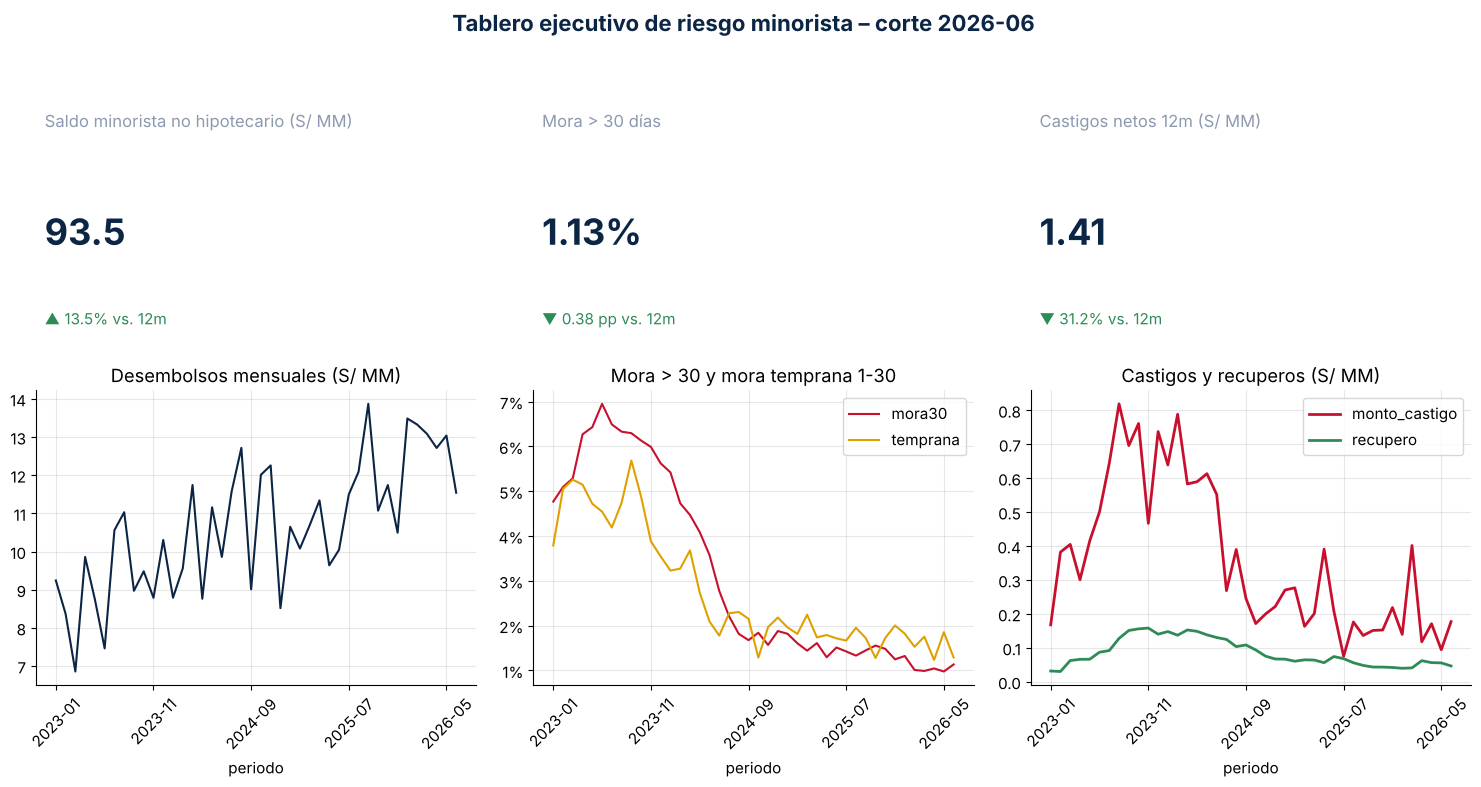

In [10]:
cons = vig[vig.producto != "Hipotecario"]
k = cons.groupby("periodo").apply(lambda d: pd.Series({"saldo": d.saldo.sum() / 1e6,
        "mora30": d.loc[d.dias_atraso > 30, "saldo"].sum() / d.saldo.sum(),
        "temprana": d.loc[d.dias_atraso.between(1, 30), "saldo"].sum() / d.saldo.sum()})).loc["2023-01":CORTE]
castm = p[p.producto != "Hipotecario"].groupby("periodo")[["monto_castigo", "recupero"]].sum().loc["2023-01":CORTE] / 1e6
desemb = p[p.mob == 1].groupby("periodo").monto_desembolsado.sum().loc["2023-01":CORTE] / 1e6

fig = plt.figure(figsize=(15, 8)); gs = fig.add_gridspec(2, 3)
def kpi(ax, titulo, valor, delta, bueno_si_baja=True, pp=False):
    ax.axis("off"); col = VERDE if (delta < 0) == bueno_si_baja else ROJO
    ax.text(0.02, 0.75, titulo, fontsize=12, color=GRIS); ax.text(0.02, 0.35, valor, fontsize=26, weight="bold", color=AZUL)
    ax.text(0.02, 0.08, f"{'▲' if delta > 0 else '▼'} " + (f"{abs(delta)*100:.2f} pp" if pp else f"{abs(delta):.1%}") + " vs. 12m", fontsize=11, color=col)
kpi(fig.add_subplot(gs[0, 0]), "Saldo minorista no hipotecario (S/ MM)", f"{k.saldo.iloc[-1]:,.1f}", k.saldo.iloc[-1] / k.saldo.iloc[-13] - 1, bueno_si_baja=False)
kpi(fig.add_subplot(gs[0, 1]), "Mora > 30 días", f"{k.mora30.iloc[-1]:.2%}", k.mora30.iloc[-1] - k.mora30.iloc[-13], pp=True)
kpi(fig.add_subplot(gs[0, 2]), "Castigos netos 12m (S/ MM)", f"{(castm.monto_castigo - castm.recupero).iloc[-12:].sum():,.2f}",
    (castm.monto_castigo - castm.recupero).iloc[-12:].sum() / (castm.monto_castigo - castm.recupero).iloc[-24:-12].sum() - 1)
ax1 = fig.add_subplot(gs[1, 0]); desemb.plot(ax=ax1, color=AZUL); ax1.set_title("Desembolsos mensuales (S/ MM)"); ax1.tick_params(axis="x", rotation=45)
ax2 = fig.add_subplot(gs[1, 1]); k[["mora30", "temprana"]].plot(ax=ax2, color=[ROJO, ORO]); ax2.set_title("Mora > 30 y mora temprana 1-30"); ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax2.tick_params(axis="x", rotation=45)
ax3 = fig.add_subplot(gs[1, 2]); castm.plot(ax=ax3, color=[ROJO, VERDE], lw=2); ax3.set_title("Castigos y recuperos (S/ MM)"); ax3.tick_params(axis="x", rotation=45)
fig.suptitle(f"Tablero ejecutivo de riesgo minorista – corte {CORTE}", fontsize=16, weight="bold", color=AZUL)
plt.tight_layout(); plt.show()

## 6. Caso de discusión (en grupos, 10 minutos)
*El gerente comercial propone bajar el punto de corte de 415 a 365 para todos los canales, con el argumento de que "la mora está en mínimos históricos". Finanzas pide crecer 20 % en el año y Cobranzas advierte que su capacidad operativa está al 95 %.*

1. ¿Qué indicadores del tablero apoyan y cuáles contradicen el argumento comercial? (Pista: mora contable vs. cosechas recientes.)
2. ¿Qué evidencia del *champion–challenger* pedirías antes de aprobar?
3. ¿Qué condición pondrías desde Riesgos (límites, canal, monitoreo, *rollback*)?
4. ¿Cómo involucras a Finanzas (provisiones y presupuesto) y a Cobranzas (capacidad)?

---
**Cierre del Módulo 1:** ya tenemos el lenguaje del negocio (ciclo, apetito, indicadores, gobierno). En el **Módulo 2** construiremos el lenguaje **probabilístico** que sostiene los modelos de PD.